![Banner](../../../../Images/Banner/03_spatial_analysis/03_07_banner_spatial_causal.png)

# Geographic Regression Discontinuity



This notebook estimates a policy effect at a state border, where treatment
switches on abruptly and other conditions change smoothly. Scenario B follows
the 2024 Medicaid-expansion borders: the assignment is real, and the jump in
diabetes is simulated. The last section turns to the real uninsured share, where
no ground truth exists.

The estimator is a sharp geographic regression discontinuity, with an
Imbens-Kalyanaraman bandwidth, segment fixed effects, and boundary-point
effects. The class is `GeographicRDD` in `geolattice.spatial_analysis.spatialcausal`.



## Table of Contents

- [Overview](#overview)
- [The sharp RDD](#the-sharp-rdd)
- [A pre-existing discontinuity in the real data](#a-pre-existing-discontinuity-in-the-real-data)
- [Validity checks](#validity-checks)
- [How the effect varies along the border](#how-the-effect-varies-along-the-border)
- [Real-data application: uninsurance at expansion borders](#real-data-application-uninsurance-at-expansion-borders)
- [Summary and Conclusions](#summary-and-conclusions)
- [Resources](#resources)


## Overview

State borders are natural experiments: a state policy switches on abruptly at the border, while
geography, climate and most social conditions change smoothly across it. Comparing counties
**just on either side** identifies the policy's effect *at the border*.

**Scenario B.** A hypothetical state policy whose map follows the 2024 Medicaid-expansion map:
41 jurisdictions (including DC) had adopted expansion and 10 had not (AL, FL, GA, KS, MS, SC, TN,
TX, WI, WY) ([KFF](https://www.kff.org/medicaid/status-of-state-medicaid-expansion-decisions/)).
The **assignment is real; the effect on diabetes is simulated**:

$$Y_i=Y_i(0)+\big(-0.6+0.3\cos(2\pi p_i)\big)\,T_i^{\text{state}},$$

where $p_i\in[0,1]$ is the position of county $i$'s nearest border point along the border, so the
jump varies along the border. $Y_i(0)$ is the real 2024 diabetes prevalence plus the smooth $U$.

At the end we analyse a **real** outcome, the uninsured share, for which no ground truth exists.


**Installation.** This notebook needs installation option 3 (core, spatial analysis and spatial statistics): `pip install "geolattice[statistics]"`. See "Installation options" in the GeoLattice README.

border length: 10,812 km;  counties in expansion states: 2139 of 3109


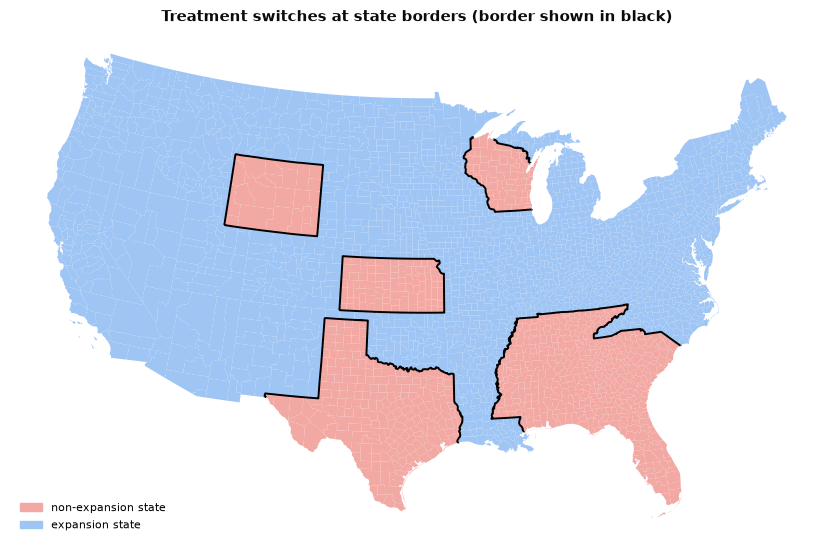

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import geopandas as gpd
import geolattice.spatial_analysis.spatialcausal as sc, countycausal as cc, tutorial_style as ts
from geolattice.spatial_analysis.spatialcausal import viz
ts.use()

gB, border, tb = cc.scenario_state_policy()
xy = cc.coords_km(gB)
T = gB["T_state"].to_numpy()
print(f"border length: {border.length:,.0f} km;  counties in expansion states: {T.sum()} of {len(T)}")
fig, ax = plt.subplots(figsize=(10, 5.6))
ts.county_map(gB, "T_state", ax, categorical=True, colors=["#f2a8a3", "#9ec5f4"],
              legend_labels=["non-expansion state", "expansion state"],
              title="Treatment switches at state borders (border shown in black)")
gpd.GeoSeries([border], crs=None).scale(1000, 1000, origin=(0, 0)).plot(ax=ax, color="black", lw=1.4)
plt.tight_layout()

***
## The sharp RDD

Let the **running variable** be the signed distance to the border,

$$r_i=\begin{cases}+\,d(s_i,\mathcal B) & T_i=1\\ -\,d(s_i,\mathcal B) & T_i=0,\end{cases}$$

so treatment is a deterministic function of location, $T_i=\mathbb 1\{r_i\ge 0\}$ (a *sharp* design).
If both potential-outcome regressions $\mathbb E[Y(t)\mid r]$ are continuous at $r=0$, then

$$\tau_{\text{RD}}=\lim_{r\downarrow0}\mathbb E[Y\mid r]-\lim_{r\uparrow0}\mathbb E[Y\mid r]=\mathbb E[Y(1)-Y(0)\mid r=0].$$

**Estimation: local linear regression.** With a kernel $K$ and bandwidth $h$, solve

$$\min_{\alpha,\tau,\beta_0,\beta_1}\sum_i K\!\Big(\frac{r_i}{h}\Big)\Big(Y_i-\alpha-\tau T_i-\beta_0r_i-\beta_1r_iT_i\Big)^2,$$

a separate line on each side. $\hat\tau$ is the gap between the two intercepts. The triangular kernel
$K(u)=(1-|u|)_+$ is optimal for estimation at a boundary point.

**Bandwidth.** Imbens & Kalyanaraman (2012) minimise the asymptotic MSE,

$$h_{\text{IK}}=C_K\left[\frac{\sigma^2_-+\sigma^2_+}{f(0)\,\big\{(m''_+-m''_-)^2+r_++r_-\big\}}\right]^{1/5}n^{-1/5},$$

with $f(0)$ the density of $r$ at the border, $\sigma^2_\pm$ the conditional variances,
$m''_\pm$ the curvatures of each side and $r_\pm$ regularisation terms. ($C_K=3.44$ for the
triangular kernel.)

**Inference.** $\hat\tau$ is a weighted least-squares coefficient with influence contributions
$\psi_i=n\,[(A^\top WA)^{-1}a_i]_\tau\,w_i\hat e_i$, so heteroskedasticity-robust and Conley standard
errors follow as in notebook 01.

### Geography-specific additions

* **Segment fixed effects** (Dell, 2010): cut the border into $S$ segments and add a dummy for each
  county's nearest segment, so treated and control counties are compared only along the *same
  stretch* of border, not Texas against Wisconsin.
* **Boundary-point effects** (Keele & Titiunik, 2015): at a point $b$ on the border, fit a local
  linear regression in the *two* coordinates on each side, with weights in the Euclidean distance
  to $b$; the effect at $b$ is the difference of the intercepts. This traces how the effect varies
  along the border.


***
## A pre-existing discontinuity in the real data

Before adding any simulated effect, run the RDD on the real 2024 diabetes prevalence. State borders
bundle many differences (other state policies, how survey-based county estimates are produced), so
real outcomes can already jump.


In [2]:
def fit(yv, **kw):
    return sc.GeographicRDD(border, se="conley", cutoff=100, **kw).fit(None, T, gB[yv].to_numpy(), xy)

rows = {}
for name, col in [("real diabetes (no simulated effect)", "diabetes_pct"), ("Y(0) = real + smooth U", "y0"),
                  ("simulated outcome Y", "y_rdd")]:
    for seg in (None, 20):
        r = fit(col, n_segments=seg)
        e = r.result_["effect_at_boundary"]
        rows[(name, "none" if seg is None else "20 segments")] = {"jump": e.estimate, "se (Conley)": e.se,
                                                                     "bandwidth km": r.bandwidth_,
                                                                     "counties in bandwidth": r.result_._stats["n_in_bandwidth"]}
pd.DataFrame(rows).T.round(3)

jump  se (Conley)  \
real diabetes (no simulated effect) none        -0.359        0.329   
                                    20 segments -0.221        0.231   
Y(0) = real + smooth U              none        -0.319        0.369   
                                    20 segments -0.180        0.238   
simulated outcome Y                 none        -0.979        0.374   
                                    20 segments -0.842        0.244   

                                                 bandwidth km  \
real diabetes (no simulated effect) none              133.615   
                                    20 segments       133.615   
Y(0) = real + smooth U              none              133.045   
                                    20 segments       133.045   
simulated outcome Y                 none              136.625   
                                    20 segments       136.625   

                                                 counties in bandwidth  
real diabetes (no simulated effect) none                        1135.0  
                                    20 segments                 1135.0  
Y(0) = real + smooth U              none                        1133.0  
                                    20 segments                 1133.0  
simulated outcome Y                 none                        1166.0  
                                    20 segments                 1166.0

The real data show a small negative jump that is not statistically significant (and smaller with
segment fixed effects). The simulated outcome's jump combines that pre-existing discontinuity with
the simulated effect.

### What is the true estimand?

The simulated jump varies along the border, so the RDD estimand is a weighted average of
$-0.6+0.3\cos(2\pi p_i)$ over the counties that drive the estimate: those near the border, weighted
by the kernel. A **difference in discontinuities**, the jump in $Y$ minus the jump in $Y(0)$ at the
same bandwidth, removes the pre-existing discontinuity. This is only possible in a simulation;
with real data one would use pre-policy outcomes instead.


In [3]:
r_y = fit("y_rdd", n_segments=20)
h = r_y.bandwidth_
r0 = sc.GeographicRDD(border, bandwidth=h, n_segments=20, se="conley", cutoff=100).fit(None, T, gB["y0"].to_numpy(), xy)
k = np.clip(1 - np.abs(r_y.running_) / h, 0, None)
true_jump = tb["jump_at"](gB["border_pos"].to_numpy())
target = np.sum(k * true_jump) / np.sum(k)
did = r_y.effect() - r0.effect()
print(f"jump in Y: {r_y.effect():.3f}   jump in Y(0): {r0.effect():.3f}   difference: {did:.3f}")
print(f"kernel-weighted true jump among counties near the border: {target:.3f}")

jump in Y: -0.842   jump in Y(0): -0.181   difference: -0.661
kernel-weighted true jump among counties near the border: -0.645


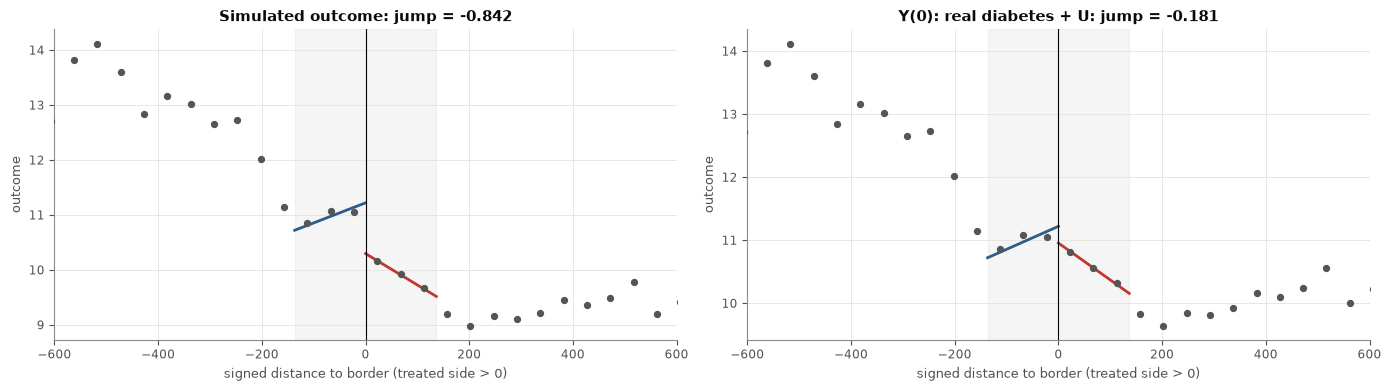

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
viz.plot_rdd(r_y, ax=ax[0], n_bins=40, title="Simulated outcome")
ax[0].set_xlim(-600, 600)
viz.plot_rdd(r0, ax=ax[1], n_bins=40, title="Y(0): real diabetes + U")
ax[1].set_xlim(-600, 600)
plt.tight_layout()

***
## Validity checks

**Covariate balance.** Pre-treatment covariates should not jump at the border. We run the same RDD
with each covariate as the outcome. One covariate needs care: **the uninsured share is itself
affected by Medicaid expansion**, so it is a *post-treatment* variable. A jump in it is an effect of
the real policy, not a failure of the design, and it must not be used as a control.


In [5]:
bal = r_y.balance(gB[cc.COVARIATES].to_numpy(), names=cc.COVARIATES)
bal["flag"] = np.where(bal.p_value < 0.05, "jumps at border", "")
bal.round(3)

,jump,se,p_value,flag
covariate,,,,
log_income,-0.019,0.026,0.453,
uninsured_pct,-1.244,0.275,0.000,jumps at border
rural_pct,-1.871,3.792,0.622,
age65_pct,0.053,0.546,0.923,
unemployment_pct,-0.269,0.145,0.063,
child_poverty_pct,0.734,1.066,0.491,
smoking_pct,0.056,0.506,0.912,
inactivity_pct,-0.083,0.702,0.905,
obesity_pct,0.886,0.496,0.074,


Apart from uninsurance, no covariate jumps at the 5% level once border segments are compared;
unemployment and obesity are borderline (p ≈ 0.06-0.07, and both are significant without segment
fixed effects).
State borders are **compound treatments**: many state policies change at the same line, so a real
border RDD identifies the effect of the whole bundle. Our simulated effect is identified only
because we know it is the sole simulated difference.

**Bandwidth sensitivity.** A credible estimate should not depend heavily on $h$.


,multiplier,bandwidth,estimate,se,ci_lower,ci_upper,n_in_bandwidth
0,0.50,68.312,-0.937,0.315,-1.555,-0.320,633
1,0.75,102.469,-0.814,0.255,-1.313,-0.315,911
2,1.00,136.625,-0.842,0.244,-1.321,-0.363,1166
3,1.50,204.937,-0.751,0.241,-1.225,-0.278,1610
4,2.00,273.250,-0.625,0.236,-1.087,-0.163,1970


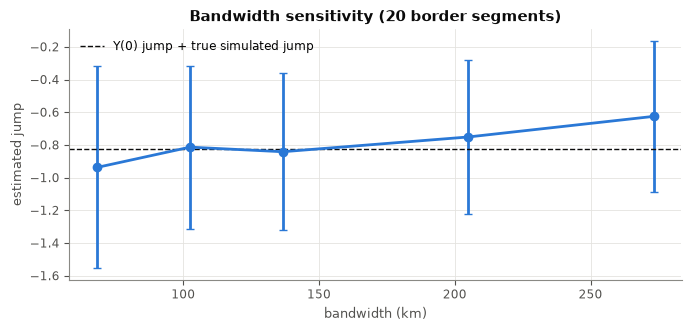

In [6]:
sens = r_y.bandwidth_sensitivity((0.5, 0.75, 1.0, 1.5, 2.0))
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.errorbar(sens.bandwidth, sens.estimate, yerr=1.96 * sens.se, fmt="o-", capsize=3, color=ts.BLUE)
ax.axhline(r0.effect() + target, color=ts.TRUTH, ls="--", lw=1, label="Y(0) jump + true simulated jump")
ax.set_xlabel("bandwidth (km)"); ax.set_ylabel("estimated jump"); ax.legend()
ax.set_title("Bandwidth sensitivity (20 border segments)")
plt.tight_layout()
sens.round(3)

***
## How the effect varies along the border

Boundary-point estimates at 12 points along the border, compared with the true simulated jump
(plus the pre-existing local discontinuity, which this method cannot separate). Points are ordered by
position along the border geometry.


correlation of boundary-point estimates with the true jump: 0.33


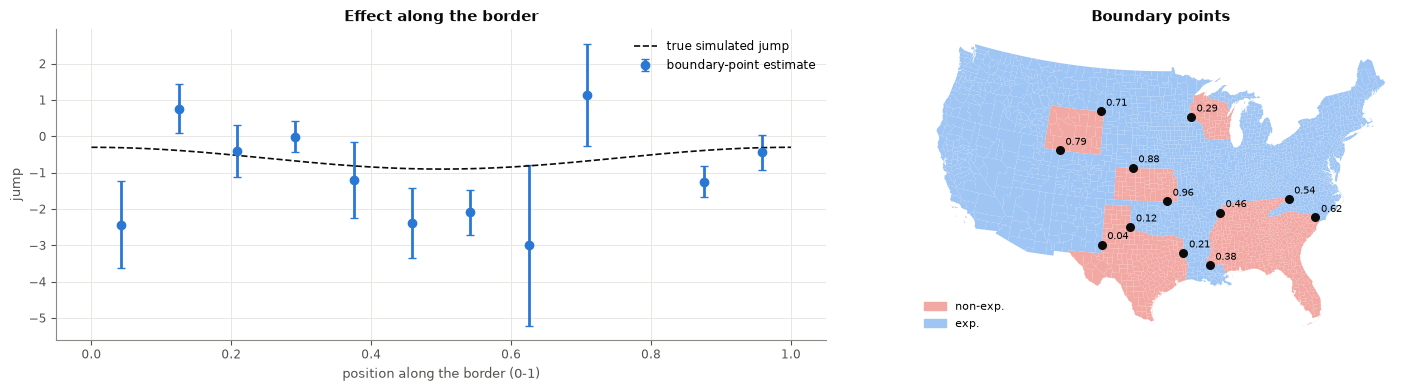

In [7]:
ab = r_y.along_boundary(12, bandwidth=2.5 * h)
ab["true simulated jump"] = tb["jump_at"](ab["position"])
fig, ax = plt.subplots(1, 2, figsize=(15, 4), gridspec_kw={"width_ratios": [1.2, 1]})
ok = ab.estimate.notna()
ax[0].errorbar(ab.position[ok], ab.estimate[ok], yerr=1.96 * ab.se[ok], fmt="o", capsize=3, color=ts.BLUE, label="boundary-point estimate")
pp = np.linspace(0, 1, 200)
ax[0].plot(pp, tb["jump_at"](pp), "--", color=ts.TRUTH, lw=1.2, label="true simulated jump")
ax[0].set_xlabel("position along the border (0-1)"); ax[0].set_ylabel("jump"); ax[0].legend()
ax[0].set_title("Effect along the border")
ts.county_map(gB, "T_state", ax[1], categorical=True, colors=["#f2a8a3", "#9ec5f4"], legend_labels=["non-exp.", "exp."])
ax[1].scatter(ab.x * 1000, ab.y * 1000, c=ts.INK, s=30, zorder=5)
for _, r in ab.iterrows():
    ax[1].annotate(f"{r.position:.2f}", (r.x * 1000, r.y * 1000), fontsize=7.5, xytext=(4, 4), textcoords="offset points")
ax[1].set_title("Boundary points")
plt.tight_layout()
print(f"correlation of boundary-point estimates with the true jump: "
      f"{np.corrcoef(ab.estimate[ok], ab['true simulated jump'][ok])[0, 1]:.2f}")

Boundary-point estimates are noisy: each uses only the counties near one point, and real
discontinuities in $Y(0)$ vary along the border too. They are useful for spotting where an effect
concentrates, not for precise local claims.

***
## Real-data application: uninsurance at expansion borders

Now a real outcome with no simulated effect: the share of the population without health insurance
(CHR 2024; small-area estimates). Medicaid expansion is designed to reduce uninsurance, so we expect
a negative jump entering expansion states.


In [8]:
pre = [c for c in cc.COVARIATES if c != "uninsured_pct"]
out = {}
for seg in (None, 20):
    for donut in (0, 25):
        r = sc.GeographicRDD(border, n_segments=seg, donut=donut, se="conley", cutoff=100).fit(
            gB[pre].to_numpy(), T, gB["uninsured_pct"].to_numpy(), xy)
        e = r.result_["effect_at_boundary"]
        out[f"segments={seg or 0}, donut={donut} km"] = {"jump (points)": e.estimate, "se": e.se, "bandwidth km": r.bandwidth_}
real = pd.DataFrame(out).T
real.round(3)

,jump (points),se,bandwidth km
"segments=0, donut=0 km",-1.519,0.388,201.395
"segments=0, donut=25 km",-1.345,0.528,201.395
"segments=20, donut=0 km",-1.300,0.259,201.395
"segments=20, donut=25 km",-1.455,0.355,201.395


Uninsurance is about 1.3-1.5 percentage points lower just inside expansion states (relative to a
mean of about 5.3%), stable across segment fixed effects and a 25 km "donut" that drops the
counties closest to the border.

Caveats before reading this causally:

* **Compound treatment.** Expansion and non-expansion states differ in many other policies at the
  same border.
* **Measurement.** County uninsurance in CHR comes from model-based small-area estimates, which can
  borrow strength within states and so may sharpen jumps at state lines.
* **County size.** Counties are large and their centroids are a coarse running variable.

It is a well-posed descriptive discontinuity consistent with the expected direction, not a
definitive estimate of the expansion effect.

***
## Summary and Conclusions

1. A border RDD compares like with like, but only at the border, and only for the bundle of
   everything that changes there.
2. Check the outcome for discontinuities that exist without the policy (placebos, pre-period data)
   and use segment fixed effects to compare along the same stretch of border.
3. Exclude post-treatment variables from covariates and balance tests.
4. Report bandwidth sensitivity. Effects along the border are informative but noisy.


***
## Resources

### Papers

| Reference | Notes |
|-----------|-------|
| Imbens & Kalyanaraman (2012) | Bandwidth that minimises asymptotic MSE |
| Dell (2010) | Border-segment fixed effects |
| Keele & Titiunik (2015) | Effects at points along a geographic boundary |
| [KFF Medicaid expansion status](https://www.kff.org/medicaid/status-of-state-medicaid-expansion-decisions/) | 2024 expansion map used as the real assignment |

### In this library

| Object | Role |
|--------|------|
| `GeographicRDD` | Local linear RDD on signed distance to the border |
| `viz.plot_rdd` | Binned scatter and the fitted lines on each side |
| `cc.scenario_state_policy` | Scenario B: expansion borders and a simulated jump |
